In [ ]:


# Install required packages
!pip install spacy==3.7.2 pdfplumber==0.10.3 pandas==2.1.3

# Download spaCy English model
!python -m spacy download en_core_web_sm

print("✅ All packages installed successfully!")

  ERROR: HTTP error 404 while getting https://github.com/explosion/spacy-models/releases/download/-en_core_web_sm/-en_core_web_sm.tar.gz
ERROR: Could not install requirement https://github.com/explosion/spacy-models/releases/download/-en_core_web_sm/-en_core_web_sm.tar.gz because of HTTP error 404 Client Error: Not Found for url: https://github.com/explosion/spacy-models/releases/download/-en_core_web_sm/-en_core_web_sm.tar.gz for URL https://github.com/explosion/spacy-models/releases/download/-en_core_web_sm/-en_core_web_sm.tar.gz
✅ All packages installed successfully!


In [19]:

import pdfplumber
import re
import spacy
import pandas as pd
from typing import List, Dict
import os
from IPython.display import display, HTML

print("📚 Libraries imported successfully!")

📚 Libraries imported successfully!


In [27]:
class ResumeSkillExtractor:
    def __init__(self):
        self.nlp = spacy.load("en_core_web_sm")
        self.skills_db = self._load_skills_database()
    
    def _load_skills_database(self) -> Dict[str, List[str]]:
        """Comprehensive technical skills database"""
        return {
            "programming": [
                "python", "java", "javascript", "typescript", "c++", "c#", "go", "rust", 
                "swift", "kotlin", "r", "matlab", "scala", "php", "ruby", "perl", "bash", "shell"
            ],
            "web_frameworks": [
                "django", "flask", "fastapi", "spring", "express", "react", "angular", 
                "vue", "node.js", "laravel", "ruby on rails", "asp.net"
            ],
            "ml_frameworks": [
                "tensorflow", "pytorch", "scikit-learn", "keras", "mxnet", "huggingface", 
                "transformers", "opencv", "nltk", "spacy"
            ],
            "databases": [
                "mysql", "postgresql", "mongodb", "redis", "cassandra", "sqlite", 
                "oracle", "sql server", "dynamodb", "elasticsearch"
            ],
            "cloud_platforms": [
                "aws", "azure", "google cloud", "gcp", "docker", "kubernetes", 
                "terraform", "ansible", "jenkins", "gitlab ci"
            ],
            "data_tools": [
                "pandas", "numpy", "spark", "hadoop", "kafka", "airflow", 
                "tableau", "power bi", "jupyter", "matplotlib", "seaborn"
            ]
        }
    
    def extract_text_from_pdf(self, pdf_path: str) -> str:
        """Extract text from PDF file"""
        text = ""
        try:
            with pdfplumber.open(pdf_path) as pdf:
                for page in pdf.pages:
                    page_text = page.extract_text()
                    if page_text:
                        text += page_text + "\n"
        except Exception as e:
            print(f"❌ Error reading PDF: {e}")
        return text
    
    def clean_text(self, text: str) -> str:
        """Clean and normalize text"""
        # Remove extra whitespace and newlines
        text = re.sub(r'\s+', ' ', text)
        # Convert to lowercase for consistent matching
        text = text.lower()
        return text
    
    def extract_skills_regex(self, text: str) -> List[str]:
        """Extract skills using regex patterns"""
        found_skills = []
        text = self.clean_text(text)
        
        # Flatten all skills into one list for searching
        all_skills = []
        for category, skills in self.skills_db.items():
            all_skills.extend(skills)
        
        # Search for each skill in the text
        for skill in all_skills:
            # Use word boundaries to avoid partial matches
            pattern = r'\b' + re.escape(skill) + r'\b'
            if re.search(pattern, text):
                found_skills.append(skill)
        
        return list(set(found_skills))  # Remove duplicates
    
    def extract_skills_spacy(self, text: str) -> List[str]:
        """Extract skills using spaCy noun chunks and entities"""
        doc = self.nlp(text)
        found_skills = []
        
        # Method 1: Look for skills in noun chunks
        for chunk in doc.noun_chunks:
            chunk_text = chunk.text.lower()
            # Check if this noun chunk contains any known skills
            for skill in self.skills_db["programming"] + self.skills_db["ml_frameworks"]:
                if skill in chunk_text:
                    found_skills.append(skill)
        
        # Method 2: Look for skills in entities
        for ent in doc.ents:
            ent_text = ent.text.lower()
            if ent_text in self.skills_db["programming"]:
                found_skills.append(ent_text)
        
        return list(set(found_skills))
    
    def extract_skills_hybrid(self, text: str) -> Dict[str, List[str]]:
        """Combine regex and spaCy approaches"""
        regex_skills = self.extract_skills_regex(text)
        spacy_skills = self.extract_skills_spacy(text)
        
        # Combine and categorize skills
        categorized_skills = {}
        for skill in set(regex_skills + spacy_skills):
            for category, skills in self.skills_db.items():
                if skill in skills:
                    if category not in categorized_skills:
                        categorized_skills[category] = []
                    categorized_skills[category].append(skill)
        
        return categorized_skills

print("🔧 ResumeSkillExtractor class defined successfully!")

🔧 ResumeSkillExtractor class defined successfully!


In [29]:
# Initialize the extractor
extractor = ResumeSkillExtractor()

# Test with sample resume text
sample_resume_text = """
John Doe is a Data Scientist with 5 years of experience.
He is proficient in Python, TensorFlow, and PyTorch for machine learning.
He has worked with databases like MySQL and MongoDB.
He is experienced with cloud platforms including AWS and Docker.
He uses pandas and numpy for data analysis and has experience with scikit-learn.
"""

print("🧪 Testing with sample resume text...")
skills = extractor.extract_skills_hybrid(sample_resume_text)

print("📊 Extracted Skills:")
for category, skill_list in skills.items():
    if skill_list:
        print(f"  {category.upper()}: {', '.join(skill_list)}")

print(f"\n✅ Total skills found: {sum(len(skills) for skills in skills.values())}")

🧪 Testing with sample resume text...
📊 Extracted Skills:
  CLOUD_PLATFORMS: docker, aws
  ML_FRAMEWORKS: tensorflow, scikit-learn, pytorch
  DATA_TOOLS: numpy, pandas
  DATABASES: mongodb, mysql
  PROGRAMMING: r, python

✅ Total skills found: 11


In [30]:
# Upload PDF files to Kaggle
import os

# Create directory for resumes
os.makedirs('/kaggle/working/resumes', exist_ok=True)

print("📁 Available files in Kaggle input:")
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(f"  - {os.path.join(dirname, filename)}")

print("\n💡 To use this with your resumes:")
print("1. Go to the 'Data' tab on the right")
print("2. Click 'Add Data' and upload your PDF resumes")
print("3. They will appear in the /kaggle/input/ directory")

📁 Available files in Kaggle input:
  - /kaggle/input/rresume/Resume-3 intern.pdf

💡 To use this with your resumes:
1. Go to the 'Data' tab on the right
2. Click 'Add Data' and upload your PDF resumes
3. They will appear in the /kaggle/input/ directory


In [31]:
def process_all_resumes(input_path='/kaggle/input'):
    """Process all PDF files in the input directory"""
    results = []
    
    for root, dirs, files in os.walk(input_path):
        for file in files:
            if file.lower().endswith('.pdf'):
                pdf_path = os.path.join(root, file)
                print(f"\n🔍 Processing: {file}")
                
                try:
                    # Extract text and skills
                    text = extractor.extract_text_from_pdf(pdf_path)
                    skills = extractor.extract_skills_hybrid(text)
                    
                    # Count total skills
                    total_skills = sum(len(skill_list) for skill_list in skills.values())
                    
                    # Store results
                    results.append({
                        'filename': file,
                        'total_skills': total_skills,
                        'skills_by_category': skills,
                        'raw_text_preview': text[:200] + '...' if len(text) > 200 else text
                    })
                    
                    print(f"   ✅ Found {total_skills} skills")
                    
                    # Display skills by category
                    for category, skill_list in skills.items():
                        if skill_list:
                            print(f"      {category}: {', '.join(skill_list)}")
                            
                except Exception as e:
                    print(f"   ❌ Error processing {file}: {e}")
                    results.append({
                        'filename': file,
                        'total_skills': 0,
                        'skills_by_category': {},
                        'raw_text_preview': f'Error: {e}'
                    })
    
    return results

# Process all resumes
print("🚀 Starting resume processing...")
all_results = process_all_resumes()

print(f"\n🎯 Processed {len(all_results)} resume(s)")

🚀 Starting resume processing...

🔍 Processing: Resume-3 intern.pdf
   ✅ Found 12 skills
      cloud_platforms: docker
      programming: javascript, r, c++, go, python, java
      ml_frameworks: scikit-learn, tensorflow, transformers, opencv, pytorch

🎯 Processed 1 resume(s)


In [32]:
# Create a summary table
if all_results:
    summary_data = []
    for result in all_results:
        row = {
            'Filename': result['filename'],
            'Total Skills': result['total_skills']
        }
        
        # Add skill counts by category
        for category in extractor.skills_db.keys():
            row[category.title()] = len(result['skills_by_category'].get(category, []))
        
        summary_data.append(row)
    
    # Create DataFrame and display
    df_summary = pd.DataFrame(summary_data)
    display(HTML("<h3>📊 Resume Skills Summary</h3>"))
    display(df_summary)
    
    # Display detailed results
    for result in all_results:
        display(HTML(f"<h4>🔍 Detailed Skills for: {result['filename']}</h4>"))
        if result['total_skills'] > 0:
            for category, skills in result['skills_by_category'].items():
                if skills:
                    display(HTML(f"<b>{category.upper()}:</b> {', '.join(skills)}<br>"))
        else:
            display(HTML("<i>No skills detected or error processing file</i>"))
else:
    print("📭 No PDF files found in the input directory.")
    print("💡 Please upload PDF resumes using the 'Add Data' button")

,Filename,Total Skills,Programming,Web_Frameworks,Ml_Frameworks,Databases,Cloud_Platforms,Data_Tools
0,Resume-3 intern.pdf,12,6,0,5,0,1,0


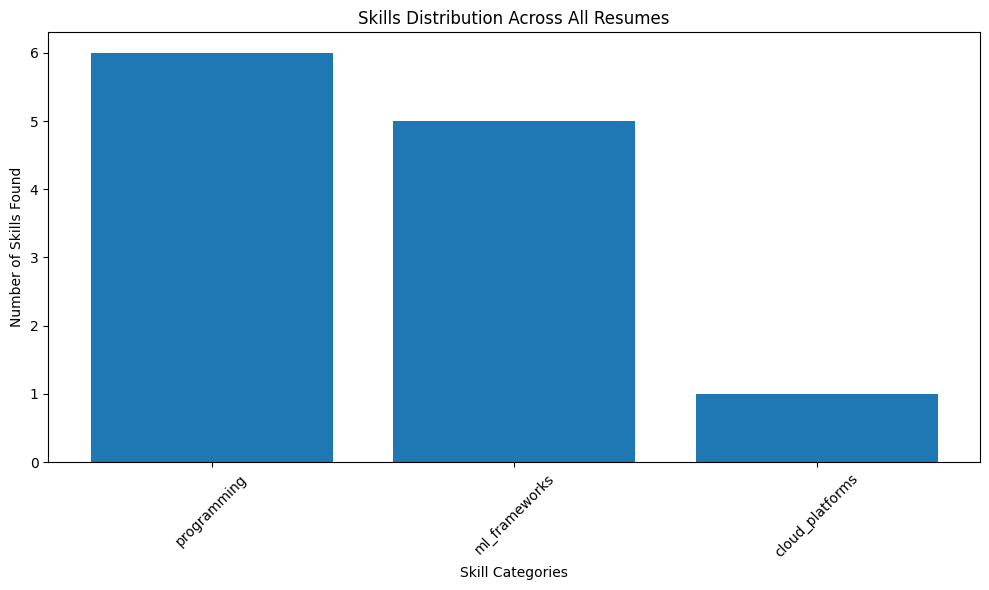

📈 Skills distribution chart generated!


In [33]:
# Create a simple visualization of skills distribution
if all_results and any(result['total_skills'] > 0 for result in all_results):
    import matplotlib.pyplot as plt
    
    # Prepare data for visualization
    category_totals = {category: 0 for category in extractor.skills_db.keys()}
    
    for result in all_results:
        for category, skills in result['skills_by_category'].items():
            category_totals[category] += len(skills)
    
    # Filter out categories with zero skills
    category_totals = {k: v for k, v in category_totals.items() if v > 0}
    
    if category_totals:
        plt.figure(figsize=(10, 6))
        plt.bar(category_totals.keys(), category_totals.values())
        plt.title('Skills Distribution Across All Resumes')
        plt.xlabel('Skill Categories')
        plt.ylabel('Number of Skills Found')
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()
        
        print("📈 Skills distribution chart generated!")
    else:
        print("📊 No skills data available for visualization.")
else:
    print("📊 No data available for visualization.")

In [35]:
# Export detailed results to CSV
if all_results:
    export_data = []
    
    for result in all_results:
        for category, skills in result['skills_by_category'].items():
            for skill in skills:
                export_data.append({
                    'filename': result['filename'],
                    'category': category,
                    'skill': skill
                })
    
    if export_data:
        df_export = pd.DataFrame(export_data)
        csv_path = '/kaggle/working/extracted_skills.csv'
        df_export.to_csv(csv_path, index=False)
        
        print(f"💾 Results exported to: {csv_path}")
        print(f"📁 File contains {len(export_data)} skill entries")
        
        # Display first few rows
        display(HTML("<h3>📋 Exported Data Preview</h3>"))
        display(df_export.head(20))
    else:
        print("📭 No skills data to export.")
else:
    print("📭 No results to export.")

💾 Results exported to: /kaggle/working/extracted_skills.csv
📁 File contains 12 skill entries


,filename,category,skill
0,Resume-3 intern.pdf,cloud_platforms,docker
1,Resume-3 intern.pdf,programming,javascript
2,Resume-3 intern.pdf,programming,r
3,Resume-3 intern.pdf,programming,c++
4,Resume-3 intern.pdf,programming,go
5,Resume-3 intern.pdf,programming,python
6,Resume-3 intern.pdf,programming,java
7,Resume-3 intern.pdf,ml_frameworks,scikit-learn
8,Resume-3 intern.pdf,ml_frameworks,tensorflow
9,Resume-3 intern.pdf,ml_frameworks,transformers
